In [1]:
# ── Fix working directory so paths work from any location ────────────────────
import os, sys

# Always resolve paths relative to the project root (one level above notebooks/)
NOTEBOOK_DIR = os.path.dirname(os.path.abspath('__file__')) if '__file__' in dir() else os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..'))
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)
print(f'✅ Working directory set to: {os.getcwd()}')


✅ Working directory set to: c:\Users\khali\Downloads\emotion_project\emotion_final


In [2]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 0 : Imports + chargement des données
# ═══════════════════════════════════════════════════════════════
import os, re, time, gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

os.environ["OMP_NUM_THREADS"]      = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"]      = "2"

plt.rcParams['figure.dpi']  = 100
plt.rcParams['font.family'] = 'DejaVu Sans'

df_train_raw = pd.read_csv('data/raw/train.csv')
df_val_raw   = pd.read_csv('data/raw/val.csv')
df_test_raw  = pd.read_csv('data/raw/test.csv')

# Reconstruction emotion_mapping
emotion_mapping = {}
with open('data/raw/emotions.txt', 'r') as f:
    for idx, line in enumerate(f):
        name = line.strip()
        if name:
            emotion_mapping[idx] = name

import ast

def parse_labels(val):
    if isinstance(val, list):
        return val
    nums = re.findall(r'\d+', str(val))
    return [int(n) for n in nums] if nums else [27]
df_train = df_train_raw.copy()
df_val   = df_val_raw.copy()
df_test  = df_test_raw.copy()

for df in [df_train, df_val, df_test]:
    df['labels']  = df['labels'].apply(parse_labels)
    df['label']   = df['labels'].apply(lambda x: x[0] if len(x) > 0 else 27)
    df['emotion'] = df['label'].map(emotion_mapping)

# ── VERIFICATION ──────────────────────────────────────────────
print(f"Classes uniques dans label : {df_train['label'].nunique()}")
print(f"Exemples : {df_train['label'].head().tolist()}")


Classes uniques dans label : 28
Exemples : [27, 27, 2, 14, 3]


## 4. Prétraitement du Texte

Nettoyage du texte brut : minuscules, contractions, URLs, ponctuation, stopwords émotionnels conservés.

In [3]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 2 : Fonction de nettoyage de texte
# ═══════════════════════════════════════════════════════════════

CONTRACTIONS = {
    "won't": "will not", "can't": "cannot", "don't": "do not",
    "it's": "it is", "i'm": "i am", "you're": "you are",
    "they're": "they are", "we're": "we are", "that's": "that is",
    "what's": "what is", "who's": "who is", "there's": "there is",
    "here's": "here is", "he's": "he is", "she's": "she is",
    "how's": "how is", "where's": "where is", "when's": "when is",
    "n't": " not", "'re": " are", "'s": " is", "'d": " would",
    "'ll": " will", "'ve": " have", "'m": " am",
}

# Stopwords personnalisés — mots émotionnels conservés
MOTS_A_GARDER = {
    'not','no','nor','never','neither',
    'very','too','so','such','quite','rather',
    'extremely','absolutely','completely','totally',
    'really','truly','deeply','highly','strongly',
    'most','more','less','least','much','many',
    'but','however','although','though','yet',
    'still','despite','even','only','just'
}

# Stopwords anglais simples (sans dépendance spacy)
STOPWORDS = {
    'i','me','my','myself','we','our','ours','ourselves','you','your','yours',
    'yourself','yourselves','he','him','his','himself','she','her','hers',
    'herself','it','its','itself','they','them','their','theirs','themselves',
    'what','which','who','whom','this','that','these','those','am','is','are',
    'was','were','be','been','being','have','has','had','having','do','does',
    'did','doing','a','an','the','and','or','if','in','at','by','for','with',
    'about','against','between','into','through','during','before','after',
    'above','below','to','from','up','down','out','on','off','over','under',
    'again','then','once','here','there','when','where','why','how','all',
    'both','each','few','other','some','such','own','same','than','as','of',
    'will','would','should','shall','may','might','must','can','could',
    'get','got','go','going','come','came','say','said','make','made',
    'know','think','see','look','want','use','find','give','tell','ask',
    'seem','feel','try','leave','call','keep','let','put','mean','become',
    'show','follow','turn','live','play','run','move','pay','hear','help',
    'talk','start','return','need','like','also','just','well','back',
    'way','even','new','old','good','great','little','own','right','big'
} - MOTS_A_GARDER  # on retire les mots émotionnels

def preprocess_text(text: str) -> str:
    if not isinstance(text, str) or text.strip() == '':
        return ''
    text = text.lower().replace('\u2019', "'")
    for contraction, expansion in CONTRACTIONS.items():
        text = re.sub(re.escape(contraction), expansion, text)
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+|#\w+|r/\w+|u/\w+', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r"[^a-z\s']", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokeniser(text: str) -> list:
    """Tokenise + supprime stopwords — version légère sans spacy."""
    tokens = re.findall(r"\b[a-z']{2,}\b", text)
    return [t for t in tokens if t not in STOPWORDS]

# ── Test rapide ───────────────────────────────────────────────
tests = [
    "I am so ANGRY at this stupid system!!! http://example.com",
    "I'm NOT happy at all — this is won't work!",
    "r/python has 1000 tips, loved it! @user #blessed",
]
print('📝 Tests :')
for t in tests:
    cleaned = preprocess_text(t)
    tokens  = tokeniser(cleaned)
    print(f'  AVANT   : {t}')
    print(f'  APRÈS   : {cleaned}')
    print(f'  TOKENS  : {tokens}')
    print()


📝 Tests :
  AVANT   : I am so ANGRY at this stupid system!!! http://example.com
  APRÈS   : i am so angry at this stupid system
  TOKENS  : ['so', 'angry', 'stupid', 'system']

  AVANT   : I'm NOT happy at all — this is won't work!
  APRÈS   : i am not happy at all this is will not work
  TOKENS  : ['not', 'happy', 'not', 'work']

  AVANT   : r/python has 1000 tips, loved it! @user #blessed
  APRÈS   : has tips loved it
  TOKENS  : ['tips', 'loved']



In [4]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 3 : Application du prétraitement (rapide, vectorisé)
# ═══════════════════════════════════════════════════════════════

print('⏳ Nettoyage des textes...')
t0 = time.time()

for df in [df_train, df_val, df_test]:
    df['text_clean'] = df['text'].apply(preprocess_text)

print(f'✅ Nettoyage terminé en {time.time()-t0:.1f}s')

# Suppression des textes vides
for nom, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    n_avant = len(df)
    df.drop(df[df['text_clean'].str.strip() == ''].index, inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f'   [{nom}] textes vides supprimés : {n_avant - len(df)}')

print()
print(f'   df_train_raw.shape = {df_train_raw.shape}  ← original intact')
print(f'   df_train.shape     = {df_train.shape}  ← copie de travail')

# Tokenisation légère (sans spacy)
print('\n⏳ Tokenisation...')
t0 = time.time()
for df in [df_train, df_val, df_test]:
    df['text_tokens'] = df['text_clean'].apply(tokeniser)
print(f'✅ Tokenisation terminée en {time.time()-t0:.1f}s')
gc.collect()

print('\n📋 Aperçu :')
df_train[['text', 'text_clean', 'text_tokens', 'emotion']].head(5)


⏳ Nettoyage des textes...
✅ Nettoyage terminé en 5.4s
   [train] textes vides supprimés : 9
   [val] textes vides supprimés : 2
   [test] textes vides supprimés : 2

   df_train_raw.shape = (43410, 3)  ← original intact
   df_train.shape     = (43401, 6)  ← copie de travail

⏳ Tokenisation...
✅ Tokenisation terminée en 0.6s

📋 Aperçu :


,text,text_clean,text_tokens,emotion
0,My favourite food is anything I didn't have to...,my favourite food is anything i did not have t...,"[favourite, food, anything, not, cook]",neutral
1,"Now if he does off himself, everyone will thin...",now if he does off himself everyone will think...,"[now, everyone, hes, laugh, screwing, people, ...",neutral
2,WHY THE FUCK IS BAYLESS ISOING,why the fuck is bayless isoing,"[fuck, bayless, isoing]",anger
3,To make her feel threatened,to make her feel threatened,[threatened],fear
4,Dirty Southern Wankers,dirty southern wankers,"[dirty, southern, wankers]",annoyance


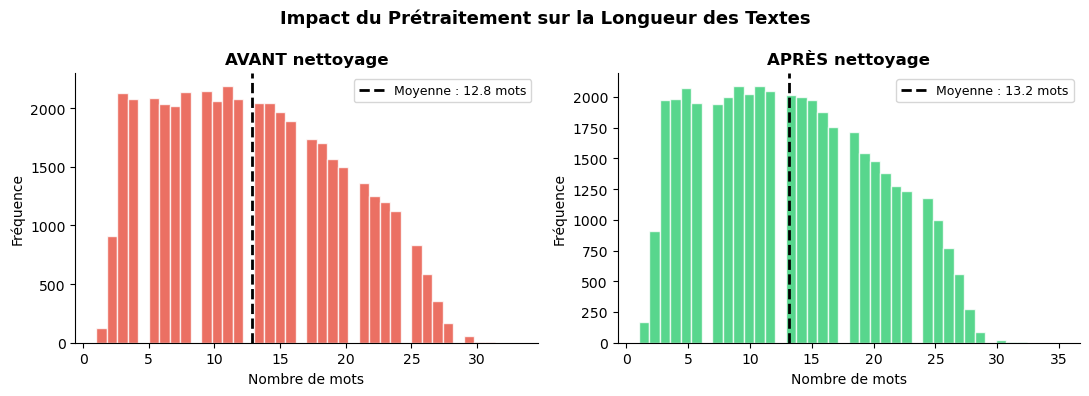

📉 Réduction : 12.8 → 13.2 mots en moyenne


122

In [5]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 4 : Comparaison longueur avant / après prétraitement
# ═══════════════════════════════════════════════════════════════

df_train['word_count']  = df_train['text'].str.split().str.len().fillna(0).astype(int)
df_train['words_after'] = df_train['text_clean'].str.split().str.len().fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Impact du Prétraitement sur la Longueur des Textes',
             fontsize=13, fontweight='bold')

for ax, col, color, titre in [
    (axes[0], 'word_count',  '#E74C3C', 'AVANT nettoyage'),
    (axes[1], 'words_after', '#2ECC71', 'APRÈS nettoyage')
]:
    mean_val = df_train[col].mean()
    ax.hist(df_train[col], bins=40, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(mean_val, color='black', linestyle='--', linewidth=2,
               label=f'Moyenne : {mean_val:.1f} mots')
    ax.set_title(titre, fontweight='bold')
    ax.set_xlabel('Nombre de mots')
    ax.set_ylabel('Fréquence')
    ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('fig5_avant_apres_nettoyage.png', bbox_inches='tight')
plt.show()
print(f'📉 Réduction : {df_train["word_count"].mean():.1f} → {df_train["words_after"].mean():.1f} mots en moyenne')

# Libérer colonnes temporaires
df_train.drop(columns=['word_count', 'words_after'], inplace=True, errors='ignore')
gc.collect()


## 5. Vectorisation TF-IDF

**TF-IDF** (Term Frequency × Inverse Document Frequency) convertit le texte en vecteurs numériques.
Un mot fréquent dans un document ET rare dans le corpus → score élevé.

In [6]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 6 : Vectorisation TF-IDF
# ═══════════════════════════════════════════════════════════════

from sklearn.feature_extraction.text import TfidfVectorizer
import gc

# Joindre les tokens en string pour TF-IDF
def tokens_to_str(tokens):
    if isinstance(tokens, list):
        return ' '.join(tokens)
    return str(tokens) if pd.notna(tokens) else ''

train_texts = df_train['text_tokens'].apply(tokens_to_str)
val_texts   = df_val['text_tokens'].apply(tokens_to_str)
test_texts  = df_test['text_tokens'].apply(tokens_to_str)

tfidf = TfidfVectorizer(
    max_features = 15000,
    min_df       = 3,
    max_df       = 0.90,
    sublinear_tf = True,
    ngram_range  = (1, 1),
)

print('⏳ Fitting TF-IDF...')
t0 = time.time()
X_train = tfidf.fit_transform(train_texts)
X_val   = tfidf.transform(val_texts)
X_test  = tfidf.transform(test_texts)
print(f'✅ Terminé en {time.time()-t0:.1f}s')
gc.collect()

y_train = df_train['label'].values
y_val   = df_val['label'].values
y_test  = df_test['label'].values

print(f'\n✅ Vectorisation terminée')
print(f'   Vocabulaire : {len(tfidf.vocabulary_):,} tokens')
print(f'   X_train     : {X_train.shape}')
print(f'   X_val       : {X_val.shape}')
print(f'   X_test      : {X_test.shape}')


⏳ Fitting TF-IDF...
✅ Terminé en 0.7s

✅ Vectorisation terminée
   Vocabulaire : 9,085 tokens
   X_train     : (43401, 9085)
   X_val       : (5424, 9085)
   X_test      : (5425, 9085)


In [7]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 7 : Sauvegarde des données nettoyées dans data/processed/
# ═══════════════════════════════════════════════════════════════

import os, joblib
os.makedirs('data/processed', exist_ok=True)
os.makedirs('models',         exist_ok=True)

for split, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    df_save = df[['id', 'text', 'text_clean', 'label', 'emotion']].copy()
    df_save['text_tokens'] = df['text_tokens'].apply(
        lambda x: ' '.join(x) if isinstance(x, list) else str(x))
    df_save.to_csv(f'data/processed/{split}_clean.csv', index=False)

# Sauvegarder aussi le vectoriseur TF-IDF pour run_pipeline.py
joblib.dump(tfidf, 'models/tfidf_vectorizer.joblib')

print('✅ Fichiers sauvegardés :')
print('   data/processed/train_clean.csv')
print('   data/processed/val_clean.csv')
print('   data/processed/test_clean.csv')
print('   models/tfidf_vectorizer.joblib')


✅ Fichiers sauvegardés :
   data/processed/train_clean.csv
   data/processed/val_clean.csv
   data/processed/test_clean.csv
   models/tfidf_vectorizer.joblib
